# V5 — Teste de segmentação temporal: KDE + SVM RBF

**Objetivo:** comparar o KDE treinado com gravações completas de **5 s** e com **duas metades de 2,5 s**, sem misturar gravações entre treinamento, validação e teste.

**Como executar:** siga as células em ordem. As primeiras células foram reaproveitadas da V4 (até a construção de `df_C`); as seguintes constituem um experimento independente, sem reutilizar os KDEs ou a SVM da V4.

**Protocolo:** folds oficiais do ESC-50: 1–3 = treinamento normal dos KDEs, 4 = desenvolvimento da fusão SVM, 5 = avaliação externa. Toda otimização usa os dados permitidos da respectiva etapa. A comparação final usa a gravação completa como unidade, inclusive no modelo segmentado.

**Atenção:** nenhuma métrica final foi executada neste arquivo. Os resultados serão produzidos ao rodar o notebook com o dataset.

In [1]:
!test -d ESC-50 || git clone https://github.com/karolpiczak/ESC-50.git

Cloning into 'ESC-50'...
remote: Enumerating objects: 4199, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 4199 (delta 62), reused 34 (delta 34), pack-reused 4130 (from 1)
Receiving objects: 100% (4199/4199), 878.77 MiB | 16.96 MiB/s, done.
Resolving deltas: 100% (292/292), done.
Updating files: 100% (2011/2011), done.


In [2]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import entropy
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

### 1. Upload do Dataset

In [3]:
caminho_csv = 'ESC-50/meta/esc50.csv'
PASTA_AUDIO = 'ESC-50/audio/'

In [4]:
df_original = pd.read_csv(caminho_csv)

Categorias
Animais (Índices 0 a 9)
0: Dog / 1: Rooster / 2: Pig / 3: Cow / 4: Frog / 5: Cat / 6: Hen / 7: Insects (flying) / 8: Sheep / 9: Crow

 Paisagens Naturais e Sons de Água (Índices 10 a 19)
 10: Rain / 11: Sea waves / 12: Crackling fire / 13: Crickets / 14: Chirping birds / 15: Water drops / 16: Wind / 17: Pouring water / 18: Toilet flush (Descarga de vaso sanitário) / 19: Thunderstorm (Tempestade com trovoada)

 Ruídos Externos / Urbanos (Índices 40 a 49)
 40: Helicopter / 41: Chainsaw / 42: Siren / 43: Car horn / 44: Engine / 45: Train / 46: Church bells / 47: Airplane / 48: Fireworks / 49: Hand saw

In [5]:
df = df_original[(df_original['target'] <= 19) | (df_original['target'] >= 40)]

In [6]:
df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
5,1-101296-B-19.wav,1,19,thunderstorm,False,101296,B
8,1-103298-A-9.wav,1,9,crow,False,103298,A


In [7]:
df.shape

(1200, 7)

### 2. Ajustes do Dataset

In [8]:
SR = 16000
COLUNA_ARQUIVO = "filename"

In [9]:
def estatisticas(vetor, prefixo):
    """
    Transforma uma série temporal em características por áudio.
    """
    vetor = np.asarray(vetor).flatten()

    return {
        f"{prefixo}_mean": np.mean(vetor),
        f"{prefixo}_std": np.std(vetor),
        f"{prefixo}_median": np.median(vetor),
        f"{prefixo}_min": np.min(vetor),
        f"{prefixo}_max": np.max(vetor),
    }

### 3. Experimento C: A + B

In [10]:
from scipy.special import xlogy
def extrair_experimento_C(caminho=None, n_mfcc=5, sr=SR, y=None):
    """Extrai atributos de caminho (5 s) OU vetor de amostras (segmento)."""
    if y is None:
        if caminho is None:
            raise ValueError("Informe caminho ou vetor de áudio y.")
        y, sr = librosa.load(caminho, sr=sr, mono=True)
    else:
        y = np.asarray(y, dtype=np.float32)
        if y.ndim != 1 or len(y) == 0:
            raise ValueError("O áudio fornecido deve ser um vetor 1-D não vazio.")

    features = {}

    # 1. MFCC
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc
    )
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                mfcc[i],
                f"mfcc_{i+1}"
            )
        )

    # 2. DELTA
    delta = librosa.feature.delta(mfcc)
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                delta[i],
                f"delta_{i+1}"
            )
        )

    # 3. DELTA-DELTA
    delta_delta = librosa.feature.delta(
        mfcc,
        order=2
    )
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                delta_delta[i],
                f"delta_delta_{i+1}"
            )
        )

    # 4. ZERO CROSSING RATE
    zcr = librosa.feature.zero_crossing_rate(y)[0]

    features.update(
        estatisticas(
            zcr,
            "zcr"
        )
    )

    # 5. SPECTRAL CENTROID
    centroid = librosa.feature.spectral_centroid(
        y=y,
        sr=sr
    )[0]
    features.update(
        estatisticas(
            centroid,
            "centroid"
        )
    )


    # 6. FREQUÊNCIA DOMINANTE
    espectro = np.abs(librosa.stft(y))
    frequencias = librosa.fft_frequencies(sr=sr)
    indice_dominante = np.argmax(
        espectro,
        axis=0
    )
    freq_dominante = frequencias[indice_dominante]
    features.update(estatisticas(freq_dominante, "freq_dominante"))

    # 7. PULSOS POR SEGUNDO
    # Usa onset detection.
    # Cada onset representa aproximadamente um evento/pulso.
    onset_frames = librosa.onset.onset_detect(y=y,sr=sr)
    duracao = librosa.get_duration(y=y, sr=sr)
    if duracao > 0:
        pulsos_por_segundo = len(onset_frames) / duracao
    else:
        pulsos_por_segundo = 0

    features["pulsos_por_segundo"] = pulsos_por_segundo

    # 8. SILÊNCIO
    rms = librosa.feature.rms(y=y)[0]
    threshold = np.max(rms) * 0.05
    frames_silenciosos = rms < threshold
    percentual_silencio = np.mean(
        frames_silenciosos
    )
    features["percentual_silencio"] = percentual_silencio

    # 9. ENTROPIA ESPECTRAL

    potencia = espectro ** 2

    soma = np.sum(
        potencia,
        axis=0,
        keepdims=True
    )

    # Normaliza somente os frames que têm energia
    probabilidade = np.divide(
        potencia,
        soma,
        out=np.zeros_like(potencia),
        where=soma > 0
    )

    # Calcula -sum(p * log(p)), tratando p=0 corretamente
    entropia = -np.sum(
        xlogy(probabilidade, probabilidade),
        axis=0
    )

    features.update(
        estatisticas(
            entropia,
            "entropia_espectral"
        )
    )

    # 10. FLUXO ESPECTRAL
    spectral_flux = librosa.onset.onset_strength(
        y=y,
        sr=sr
    )

    features.update(
        estatisticas(
            spectral_flux,
            "fluxo_espectral"
        )
    )

    return features

### 4. Dataframes Finais Gerados

In [11]:
resultados_C = []

for _, linha in df.iterrows():

    arquivo = linha[COLUNA_ARQUIVO]

    caminho = f"{PASTA_AUDIO}/{arquivo}"

    try:

        features_C = extrair_experimento_C(caminho, 5)

        # --------------------------------------------
        # Metadados
        # --------------------------------------------
        features_C["filename"] = arquivo

        # mantém a classe original
        if "target" in df.columns:
            features_C["target"] = linha["target"]

        if "category" in df.columns:
            features_C["category"] = linha["category"]

        resultados_C.append(features_C)

    except Exception as e:

        print(
            f"Erro em {arquivo}: {e}"
        )

In [12]:
df_C = pd.DataFrame(resultados_C)

print("\nExperimento C:")
print(df_C.shape)

print("\nPrimeiras colunas C:")
print(df_C.columns.tolist())


Experimento C:
(1200, 105)

Primeiras colunas C:
['mfcc_1_mean', 'mfcc_1_std', 'mfcc_1_median', 'mfcc_1_min', 'mfcc_1_max', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_2_median', 'mfcc_2_min', 'mfcc_2_max', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_3_median', 'mfcc_3_min', 'mfcc_3_max', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_4_median', 'mfcc_4_min', 'mfcc_4_max', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_5_median', 'mfcc_5_min', 'mfcc_5_max', 'delta_1_mean', 'delta_1_std', 'delta_1_median', 'delta_1_min', 'delta_1_max', 'delta_2_mean', 'delta_2_std', 'delta_2_median', 'delta_2_min', 'delta_2_max', 'delta_3_mean', 'delta_3_std', 'delta_3_median', 'delta_3_min', 'delta_3_max', 'delta_4_mean', 'delta_4_std', 'delta_4_median', 'delta_4_min', 'delta_4_max', 'delta_5_mean', 'delta_5_std', 'delta_5_median', 'delta_5_min', 'delta_5_max', 'delta_delta_1_mean', 'delta_delta_1_std', 'delta_delta_1_median', 'delta_delta_1_min', 'delta_delta_1_max', 'delta_delta_2_mean', 'delta_delta_2_std', 'delta_delta_2_median', 'delta_d

## V5-A — Partições oficiais e baseline 5 s

Os arquivos originais são divididos **antes** de qualquer segmentação. O `df_C` da V4 já fornece as características da gravação inteira. Os novos segmentos terão o mesmo `filename` da gravação de origem e uma coluna `segmento` (1 ou 2). O CV agrupa por `src_file` para manter gravações relacionadas juntas.

In [13]:
import os
import warnings
import numpy as np
import pandas as pd

meta_esc = df_original.loc[
    df_original["target"].between(0, 19) | df_original["target"].between(40, 49),
    ["filename", "target", "category", "fold", "src_file"]
].copy()

# Baseline de 5 s: reutiliza as features já extraídas na V4
if "fold" in df_C.columns:
    df_5s = df_C.copy()
else:
    df_5s = df_C.merge(meta_esc[["filename", "fold", "src_file"]], on="filename", how="inner", validate="one_to_one")

# Apenas as colunas numéricas que pertencem à extração (excluir rótulos e metadados)
colunas_features = [c for c in df_C.columns if c not in {"filename", "target", "category", "fold"}]
assert len(meta_esc) == 1200, "Número inesperado de gravações selecionadas"
assert len(df_5s) == 1200, "Verifique se todos os 1.200 arquivos foram extraídos com sucesso"
assert df_5s["filename"].is_unique
assert set(df_5s["fold"]) == {1, 2, 3, 4, 5}
assert np.isfinite(df_5s[colunas_features].to_numpy(dtype=float)).all(), "Há NaN/inf nas características de 5 s"

FOLDS_TREINO = [1, 2, 3]
FOLD_DESENV = 4
FOLD_TESTE = 5

def selecionar_particao(tabela, nome):
    if nome == "treino":
        return tabela[tabela["fold"].isin(FOLDS_TREINO)].copy().reset_index(drop=True)
    if nome == "desenv":
        return tabela[tabela["fold"] == FOLD_DESENV].copy().reset_index(drop=True)
    if nome == "teste":
        return tabela[tabela["fold"] == FOLD_TESTE].copy().reset_index(drop=True)
    raise ValueError(nome)

print("Baseline 5 s:", df_5s.shape)
print("Treino:", len(selecionar_particao(df_5s, "treino")))
print("Desenvolvimento:", len(selecionar_particao(df_5s, "desenv")))
print("Teste:", len(selecionar_particao(df_5s, "teste")))

Baseline 5 s: (1200, 107)
Treino: 720
Desenvolvimento: 240
Teste: 240


In [14]:
# Verificar NaN e infinito nas características
numericas = df_C.select_dtypes(include=[np.number]).drop(
    columns=["target", "fold", "src_file"],
    errors="ignore"
)

problemas = (
    (~np.isfinite(numericas))
    .sum()
    .sort_values(ascending=False)
)

print("Características com valores inválidos:")
print(problemas[problemas > 0])

Características com valores inválidos:
Series([], dtype: int64)


## V5-B — Extrair duas metades de cada gravação

Reutilizamos `extrair_experimento_C`, agora aceitando `y=segmento` em vez de um caminho. O áudio é lido uma só vez por arquivo e dividido exatamente na metade das amostras. O cache é salvo em pickle para evitar repetir a extração na próxima execução.

In [15]:
from tqdm.auto import tqdm

CACHE_SEGMENTOS = "v5_features_segmentos_2p5s.pkl"
REFORCAR_EXTRACAO = False

if os.path.isfile(CACHE_SEGMENTOS) and not REFORCAR_EXTRACAO:
    df_2p5s = pd.read_pickle(CACHE_SEGMENTOS)
    if "src_file" not in df_2p5s.columns:
        raise ValueError("Cache de formato antigo: altere REFORCAR_EXTRACAO=True e rode novamente")
    print("Cache recuperado:", CACHE_SEGMENTOS)
else:
    registros = []
    for item in tqdm(meta_esc.itertuples(index=False), total=len(meta_esc), desc="Segmentando ESC-50"):
        caminho = os.path.join(PASTA_AUDIO, item.filename)
        y_audio, sr_audio = librosa.load(caminho, sr=SR, mono=True)
        metade = len(y_audio) // 2
        segmentos = (y_audio[:metade], y_audio[metade:])

        for numero, y_parte in enumerate(segmentos, start=1):
            if len(y_parte) < sr_audio:  # sanidade: cada metade >= 1 segundo
                raise ValueError(f"Segmento inesperadamente curto: {item.filename}")

            atributos = extrair_experimento_C(y=y_parte, n_mfcc=5, sr=sr_audio)
            atributos.update({
                "filename": item.filename,  # ID da gravação original
                "src_file": item.src_file,  # ID da gravação Freesound de origem
                "segmento": numero,
                "target": int(item.target),
                "category": item.category,
                "fold": int(item.fold),
                "duracao_s": len(y_parte) / sr_audio,
                "energia_rms": float(np.sqrt(np.mean(y_parte.astype(np.float64) ** 2))),
            })
            registros.append(atributos)

    df_2p5s = pd.DataFrame(registros)
    df_2p5s.to_pickle(CACHE_SEGMENTOS)
    print("Cache salvo:", CACHE_SEGMENTOS)

assert len(df_2p5s) == 2400, "Esperados 2.400 segmentos"
assert df_2p5s.groupby("filename").size().eq(2).all(), "Cada gravação deve ter duas metades"
assert set(df_2p5s[colunas_features].columns) == set(colunas_features)
assert np.isfinite(df_2p5s[colunas_features].to_numpy(dtype=float)).all(), "Há NaN/inf nas características segmentadas"

# Comprova que as metades pertencem ao mesmo fold e têm o mesmo rótulo.
assert df_2p5s.groupby("filename")["fold"].nunique().eq(1).all()
assert df_2p5s.groupby("filename")["target"].nunique().eq(1).all()

print("Completo 5 s:", df_5s.shape)
print("Segmentado 2,5 s:", df_2p5s.shape)
print("Por fold, segmentos:", df_2p5s.groupby("fold").size().to_dict())
print("Por classe normal no treino:",
      df_2p5s[df_2p5s["fold"].isin(FOLDS_TREINO) & df_2p5s["target"].between(0, 19)]
      .groupby("target").size().unique())

Segmentando ESC-50:   0%|          | 0/1200 [00:00<?, ?it/s]

Cache salvo: v5_features_segmentos_2p5s.pkl
Completo 5 s: (1200, 107)
Segmentado 2,5 s: (2400, 110)
Por fold, segmentos: {1: 480, 2: 480, 3: 480, 4: 480, 5: 480}
Por classe normal no treino: [48]


## V5-C — Diagnóstico simples de energia entre as duas metades (apenas treino)

RMS não determina se o evento de interesse está presente, mas pode sinalizar gravações em que uma metade é muito menos intensa que a outra. Para conferir os casos, ouça os áudios de origem; não mude os rótulos por inspeção do conjunto de teste.

In [16]:
treino_seg = selecionar_particao(df_2p5s, "treino")
energias = treino_seg.pivot(index="filename", columns="segmento", values="energia_rms")
energias.columns = ["rms_metade_1", "rms_metade_2"]
energias["relacao_menor_maior"] = energias.min(axis=1) / (energias.max(axis=1) + 1e-12)
energias = energias.join(meta_esc.set_index("filename")[["target", "category"]])

print("Comparação de energia (apenas folds de treino):")
display(energias.groupby("category")["relacao_menor_maior"].agg(["median", "min"]).sort_values("median").head(12))
print("\nGravações com maior diferença de energia entre as metades:")
display(energias.sort_values("relacao_menor_maior").head(10))

Comparação de energia (apenas folds de treino):


,median,min
category,,
rooster,0.000403,0.000000
cow,0.320828,0.000000
car_horn,0.392870,0.000000
thunderstorm,0.452041,0.092690
cat,0.468895,0.000000
fireworks,0.559473,0.040817
hen,0.561435,0.000000
insects,0.565026,0.000000
toilet_flush,0.591740,0.248155



Gravações com maior diferença de energia entre as metades:


,rms_metade_1,rms_metade_2,relacao_menor_maior,target,category
filename,,,,,
1-110389-A-0.wav,0.048951,0.0,0.0,0,dog
1-19026-A-43.wav,0.151724,0.0,0.0,43,car_horn
2-75726-A-6.wav,0.187138,0.0,0.0,6,hen
1-19501-A-7.wav,0.071798,0.0,0.0,7,insects
1-16746-A-15.wav,0.009063,0.0,0.0,15,water_drops
1-17124-A-43.wav,0.066442,0.0,0.0,43,car_horn
3-233151-A-2.wav,0.062224,0.0,0.0,2,pig
2-65750-A-1.wav,0.212901,0.0,0.0,1,rooster
3-145382-A-1.wav,0.168425,0.0,0.0,1,rooster


## V5-D — ANOVA e correlação: selecionar 12 atributos em cada treinamento

A seleção é refeita **independentemente** para 5 s e 2,5 s, sempre usando exclusivamente sons normais dos folds 1–3. `fold`, `target`, `segmento` e RMS diagnóstico não entram nos atributos.

In [17]:
from sklearn.feature_selection import f_classif


def selecionar_12_atributos(tabela_treino, candidatos, n_atributos=12, corte_corr=0.80):
    apenas_normais = tabela_treino[tabela_treino["target"].between(0, 19)].copy()
    X = apenas_normais[candidatos].astype(float)
    y = apenas_normais["target"].to_numpy()

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        escores, _ = f_classif(X, y)

    ranking = (pd.DataFrame({"atributo": candidatos, "F_score": escores})
                 .replace([np.inf, -np.inf], np.nan)
                 .dropna(subset=["F_score"])
                 .sort_values("F_score", ascending=False))

    correlacao = X[ranking["atributo"].tolist()].corr()
    escolhidos = []
    for candidato in ranking["atributo"]:
        if all(pd.notna(correlacao.loc[candidato, anterior]) and
               abs(correlacao.loc[candidato, anterior]) < corte_corr
               for anterior in escolhidos):
            escolhidos.append(candidato)
        if len(escolhidos) == n_atributos:
            break
    if len(escolhidos) != n_atributos:
        raise ValueError(f"Só foi possível selecionar {len(escolhidos)} atributos")
    return escolhidos, ranking

atrib_5s, ranking_5s = selecionar_12_atributos(
    selecionar_particao(df_5s, "treino"), colunas_features
)
atrib_2p5s, ranking_2p5s = selecionar_12_atributos(
    selecionar_particao(df_2p5s, "treino"), colunas_features
)

print("Atributos para 5 s:", atrib_5s)
print("\nAtributos para 2,5 s:", atrib_2p5s)
print("\nAtributos em comum:", len(set(atrib_5s) & set(atrib_2p5s)))

Atributos para 5 s: ['delta_delta_1_min', 'delta_delta_3_max', 'mfcc_3_min', 'mfcc_1_mean', 'mfcc_2_max', 'mfcc_3_std', 'delta_delta_2_max', 'delta_4_std', 'mfcc_1_max', 'centroid_mean', 'centroid_max', 'mfcc_2_min']

Atributos para 2,5 s: ['delta_delta_1_std', 'delta_3_std', 'mfcc_2_min', 'mfcc_3_min', 'centroid_mean', 'mfcc_1_min', 'mfcc_2_max', 'entropia_espectral_min', 'delta_1_min', 'delta_delta_2_std', 'delta_4_std', 'delta_1_max']

Atributos em comum: 5


## V5-E — Treinar 20 KDEs por cenário

Cada especialista ajusta seu próprio `StandardScaler`, como na V4. O bandwidth é selecionado pela média dos escores **LOO apenas dos normais de treino**, sem consultar o fold de desenvolvimento ou teste. Isso evita reutilizar rótulos de validação na definição dos KDEs.

In [18]:
from scipy.special import logsumexp
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KernelDensity

BANDWIDTHS = np.geomspace(0.2, 5.0, 15)


def log_scores_loo(X, bandwidth):
    """Log-densidade normal sem autocontagem para KDE gaussiano isotrópico."""
    n, d = X.shape
    if n < 2:
        raise ValueError("KDE LOO exige ao menos duas amostras")
    D2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2)
    np.fill_diagonal(D2, np.inf)
    h = float(bandwidth)
    return (logsumexp(-D2 / (2 * h * h), axis=1)
            - np.log(n - 1)
            - (d / 2) * np.log(2 * np.pi * h * h))


def treinar_20_kdes(df_features, atributos):
    train = selecionar_particao(df_features, "treino")
    train = train[train["target"].between(0, 19)]

    modelos = {}
    scalers = {}
    referencias = {}
    registro = []
    for categoria in range(20):
        X = train.loc[train["target"] == categoria, atributos].to_numpy(dtype=float)
        scaler = StandardScaler().fit(X)
        X_std = scaler.transform(X)

        qualidade = [(log_scores_loo(X_std, h).mean(), float(h)) for h in BANDWIDTHS]
        melhor_ll, melhor_h = max(qualidade, key=lambda a: a[0])
        kde = KernelDensity(kernel="gaussian", bandwidth=melhor_h).fit(X_std)

        modelos[categoria] = kde
        scalers[categoria] = scaler
        referencias[categoria] = log_scores_loo(X_std, melhor_h)
        registro.append({"classe": categoria, "bandwidth": melhor_h,
                         "loo_loglik": melhor_ll, "n_treino": len(X)})

    return {"modelos": modelos, "scalers": scalers,
            "refs": referencias, "atributos": list(atributos),
            "tabela": pd.DataFrame(registro)}

experimento_5s = treinar_20_kdes(df_5s, atrib_5s)
experimento_2p5s = treinar_20_kdes(df_2p5s, atrib_2p5s)

print("KDE 5 s (amostras por classe):", experimento_5s["tabela"]["n_treino"].unique())
print("KDE 2,5 s (amostras por classe):", experimento_2p5s["tabela"]["n_treino"].unique())
print("\nBandwidths por classe (5 s vs 2,5 s):")
display(experimento_5s["tabela"][['classe', 'bandwidth']].merge(
    experimento_2p5s["tabela"][['classe', 'bandwidth']], on='classe', suffixes=('_5s', '_2p5s')
))

KDE 5 s (amostras por classe): [24]
KDE 2,5 s (amostras por classe): [48]

Bandwidths por classe (5 s vs 2,5 s):


,classe,bandwidth_5s,bandwidth_2p5s
0,0,0.794597,0.501697
1,1,0.794597,0.501697
2,2,0.794597,0.631385
3,3,0.794597,0.501697
4,4,0.794597,0.398647
5,5,0.794597,0.501697
6,6,0.794597,0.501697
7,7,0.794597,0.631385
8,8,0.794597,0.631385
9,9,0.794597,0.501697


## V5-F — Matriz de 40 scores por segmento ou gravação

São **20 scores robustos e 20 percentis empíricos**, todos calculados a partir dos KDEs e das referências LOO de treinamento. As anomalias do desenvolvimento são usadas apenas na fusão supervisionada.

In [19]:
def construir_matriz_fusao(df_particao, exp):
    X = df_particao[exp["atributos"]].to_numpy(dtype=float)
    classes = sorted(exp["modelos"])

    brutos = np.column_stack([
        exp["modelos"][k].score_samples(exp["scalers"][k].transform(X))
        for k in classes
    ])

    medianas = np.array([np.median(exp["refs"][k]) for k in classes])
    escalas = np.array([(np.percentile(exp["refs"][k], 75)
                         - np.percentile(exp["refs"][k], 25)) / 1.349
                        for k in classes])
    escalas = np.maximum(escalas, 1e-6)
    z_robusto = np.clip((brutos - medianas) / escalas, -10, 10)

    percentis = np.column_stack([
        np.searchsorted(np.sort(exp["refs"][k]), brutos[:, i], side="right") / len(exp["refs"][k])
        for i, k in enumerate(classes)
    ])
    return np.column_stack([z_robusto, percentis])


def meta_dataset(df_features, exp, nome):
    tabela = selecionar_particao(df_features, nome)
    X = construir_matriz_fusao(tabela, exp)
    y = (tabela["target"].to_numpy() >= 40).astype(int)
    grupos = tabela["src_file"].fillna(tabela["filename"]).astype(str).to_numpy()
    return tabela, X, y, grupos

base_dev, X_dev_5, y_dev_5, ids_dev_5 = meta_dataset(df_5s, experimento_5s, "desenv")
seg_dev, X_dev_2p5, y_dev_2p5, ids_dev_2p5 = meta_dataset(df_2p5s, experimento_2p5s, "desenv")

print("Fusão 5 s:", X_dev_5.shape, "origens distintas:", len(np.unique(ids_dev_5)))
print("Fusão 2,5 s:", X_dev_2p5.shape, "origens distintas:", len(np.unique(ids_dev_2p5)))
assert X_dev_5.shape[1] == X_dev_2p5.shape[1] == 40
assert len(np.unique(ids_dev_5)) == len(np.unique(ids_dev_2p5))
assert base_dev["filename"].nunique() == seg_dev["filename"].nunique() == 240

Fusão 5 s: (240, 40) origens distintas: 168
Fusão 2,5 s: (480, 40) origens distintas: 168


## V5-G — Otimização da SVM no fold 4, sem acesso ao fold 5

Para o modelo segmentado, **ambas as metades do mesmo áudio — e arquivos relacionados da mesma fonte Freesound — ficam na mesma fold** de validação cruzada. A busca usa ROC-AUC por **gravação original**, agregando os scores das duas metades pela média ou pelo máximo. O limiar é calibrado a partir das predições *out-of-fold* do fold 4. Esses números de desenvolvimento são exploratórios; somente a avaliação final do fold 5 permite a comparação externa.

In [20]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score


def agregar_por_arquivo(tabela, margens, metodo="mean"):
    """Produz exatamente uma previsão e um rótulo por gravação original."""
    dados = tabela[["filename", "target", "category"]].copy()
    dados["score_anomalia"] = np.asarray(margens)
    dados["y_real"] = (dados["target"] >= 40).astype(int)
    resultado = dados.groupby("filename", sort=True).agg(
        score_anomalia=("score_anomalia", metodo),
        y_real=("y_real", "first"),
        target=("target", "first"),
        category=("category", "first"),
    ).reset_index()
    assert len(resultado) == tabela["filename"].nunique()
    return resultado


def limiar_youden(y, scores):
    fpr, tpr, limiares = roc_curve(y, scores)
    validos = np.isfinite(limiares)
    validos[0] = False
    if not validos.any():
        return 0.0
    return float(limiares[np.argmax(np.where(validos, tpr - fpr, -np.inf))])


def buscar_fusao(tabela, X, y, grupos, modos_agregacao):
    cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    splits = list(cv.split(X, y, groups=grupos))
    resultados = []

    for C in [0.1, 1.0, 10.0]:
        for gamma in ["scale", 0.003, 0.03, 0.1]:
            svm = make_pipeline(StandardScaler(), SVC(
                kernel="rbf", C=C, gamma=gamma,
                class_weight="balanced", probability=False,
                random_state=42
            ))
            # Uma predição por linha, obtida sem treinar a SVM naquela gravação.
            margens_oof = cross_val_predict(
                svm, X, y, cv=splits, method="decision_function"
            )

            for modo in modos_agregacao:
                agregado = agregar_por_arquivo(tabela, margens_oof, metodo=modo)
                y_audio = agregado["y_real"].to_numpy()
                s_audio = agregado["score_anomalia"].to_numpy()
                auc = roc_auc_score(y_audio, s_audio)
                limiar = limiar_youden(y_audio, s_audio)
                bal = balanced_accuracy_score(y_audio, (s_audio >= limiar).astype(int))
                resultados.append({
                    "C": C, "gamma": gamma, "agregacao": modo,
                    "auc_dev_oof": auc, "bal_dev_oof": bal, "limiar": limiar
                })

    tabela_busca = (pd.DataFrame(resultados)
                    .sort_values(["auc_dev_oof", "bal_dev_oof"], ascending=False)
                    .reset_index(drop=True))
    melhor = tabela_busca.iloc[0]
    melhor_modelo = make_pipeline(StandardScaler(), SVC(
        kernel="rbf", C=float(melhor["C"]), gamma=melhor["gamma"],
        class_weight="balanced", probability=False, random_state=42
    ))
    melhor_modelo.fit(X, y)  # fold 4 por inteiro, depois da escolha interna
    return melhor_modelo, melhor.to_dict(), tabela_busca

svm_5s, config_5s, busca_5s = buscar_fusao(
    base_dev, X_dev_5, y_dev_5, ids_dev_5, ["mean"]
)
svm_2p5s, config_2p5s, busca_2p5s = buscar_fusao(
    seg_dev, X_dev_2p5, y_dev_2p5, ids_dev_2p5, ["mean", "max"]
)

print("Melhor configuração para 5 s:", config_5s)
print("Melhor configuração para 2,5 s:", config_2p5s)
print("\nTop-5 das duas buscas (DESENVOLVIMENTO; não é resultado final):")
display(busca_5s.head(5))
display(busca_2p5s.head(5))

Melhor configuração para 5 s: {'C': 1.0, 'gamma': 0.03, 'agregacao': 'mean', 'auc_dev_oof': 0.761640625, 'bal_dev_oof': 0.7, 'limiar': -0.14040941696929843}
Melhor configuração para 2,5 s: {'C': 1.0, 'gamma': 0.03, 'agregacao': 'mean', 'auc_dev_oof': 0.7993750000000002, 'bal_dev_oof': 0.765625, 'limiar': 0.26112991108832945}

Top-5 das duas buscas (DESENVOLVIMENTO; não é resultado final):


,C,gamma,agregacao,auc_dev_oof,bal_dev_oof,limiar
0,1.0,0.03,mean,0.761641,0.700000,-0.140409
1,1.0,scale,mean,0.759922,0.700000,0.227379
2,1.0,0.1,mean,0.739062,0.703125,-0.334430
3,10.0,0.003,mean,0.738203,0.687500,-0.144377
4,10.0,0.03,mean,0.730234,0.693750,-0.678768


,C,gamma,agregacao,auc_dev_oof,bal_dev_oof,limiar
0,1.0,0.03,mean,0.799375,0.765625,0.261130
1,1.0,scale,mean,0.799375,0.759375,0.274486
2,1.0,0.1,mean,0.795703,0.750000,-0.005584
3,10.0,0.003,mean,0.784063,0.746875,-0.002754
4,10.0,0.1,mean,0.782891,0.750000,-0.309844


## V5-H — Avaliação final no fold 5 (executar uma vez)

**Não ajuste nada depois de ver estes resultados.** Avaliamos as duas arquiteturas na mesma lista de 240 gravações do fold 5. Mesmo para o modelo segmentado, a matriz de confusão apresenta **áudios originais**, não segmentos. Os scores da SVM são margens (`decision_function`), não probabilidades calibradas.

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score


def avaliar_teste(df_features, exp, svm, config, nome):
    tabela_teste, X_test, y_test, ids = meta_dataset(df_features, exp, "teste")
    margens = svm.decision_function(X_test)
    previsoes_audio = agregar_por_arquivo(tabela_teste, margens, metodo=config["agregacao"])
    y = previsoes_audio["y_real"].to_numpy()
    s = previsoes_audio["score_anomalia"].to_numpy()
    y_pred = (s >= float(config["limiar"])).astype(int)
    previsoes_audio["pred_binaria"] = y_pred
    matriz = confusion_matrix(y, y_pred, labels=[0, 1])

    metricas = {
        "modelo": nome,
        "agregacao": config["agregacao"],
        "n_audios": len(y),
        "roc_auc": roc_auc_score(y, s),
        "acuracia": accuracy_score(y, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "recall_normal": recall_score(y, y_pred, pos_label=0),
        "recall_anomalia": recall_score(y, y_pred, pos_label=1),
        "falsos_positivos": int(matriz[0, 1]),
        "falsos_negativos": int(matriz[1, 0]),
    }
    print(f"\n{'='*60}\n{nome}\n{'='*60}")
    print("Matriz de confusão (áudios originais):\n", matriz)
    print(classification_report(y, y_pred,
                                target_names=["Normal", "Anomalia"], zero_division=0))
    return metricas, previsoes_audio

metricas_5s, predicoes_5s = avaliar_teste(
    df_5s, experimento_5s, svm_5s, config_5s, "KDE 5 s + SVM"
)
metricas_2p5s, predicoes_2p5s = avaliar_teste(
    df_2p5s, experimento_2p5s, svm_2p5s, config_2p5s,
    "KDE 2,5 s + SVM (agregação selecionada na validação)"
)

tabela_final_v5 = pd.DataFrame([metricas_5s, metricas_2p5s])
display(tabela_final_v5)

# Garantir avaliação no MESMO conjunto original em ambos os experimentos.
assert set(predicoes_5s["filename"]) == set(predicoes_2p5s["filename"])
assert len(predicoes_5s) == len(predicoes_2p5s) == 240

print("\nDiferença segmentado - 5 s (pontos percentuais):")
for metrica in ["roc_auc", "acuracia", "balanced_accuracy", "recall_normal", "recall_anomalia"]:
    diferenca = (metricas_2p5s[metrica] - metricas_5s[metrica]) * 100
    print(f"{metrica:20s}: {diferenca:+.2f} p.p.")


KDE 5 s + SVM
Matriz de confusão (áudios originais):
 [[116  44]
 [ 37  43]]
              precision    recall  f1-score   support

      Normal       0.76      0.72      0.74       160
    Anomalia       0.49      0.54      0.51        80

    accuracy                           0.66       240
   macro avg       0.63      0.63      0.63       240
weighted avg       0.67      0.66      0.67       240


KDE 2,5 s + SVM (agregação selecionada na validação)
Matriz de confusão (áudios originais):
 [[147  13]
 [ 35  45]]
              precision    recall  f1-score   support

      Normal       0.81      0.92      0.86       160
    Anomalia       0.78      0.56      0.65        80

    accuracy                           0.80       240
   macro avg       0.79      0.74      0.76       240
weighted avg       0.80      0.80      0.79       240



,modelo,agregacao,n_audios,roc_auc,acuracia,balanced_accuracy,recall_normal,recall_anomalia,falsos_positivos,falsos_negativos
0,KDE 5 s + SVM,mean,240,0.751641,0.6625,0.631250,0.72500,0.5375,44,37
1,"KDE 2,5 s + SVM (agregação selecionada na vali...",mean,240,0.837422,0.8000,0.740625,0.91875,0.5625,13,35



Diferença segmentado - 5 s (pontos percentuais):
roc_auc             : +8.58 p.p.
acuracia            : +13.75 p.p.
balanced_accuracy   : +10.94 p.p.
recall_normal       : +19.37 p.p.
recall_anomalia     : +2.50 p.p.


## V5-I — Diagnóstico dos erros e exportação da comparação

A tabela por categoria usa apenas o fold 5, depois de congelados modelos e decisões. Serve para relatar os erros; não deve ser usada para escolher novos parâmetros e voltar a chamar isso de teste independente.

In [22]:
def desempenho_por_categoria(preds, nome):
    aux = preds.copy()
    aux["acertou"] = (aux["pred_binaria"] == aux["y_real"])
    return (aux.groupby(["target", "category"])["acertou"]
            .agg(["mean", "count"])
            .reset_index()
            .rename(columns={"mean": f"taxa_acerto_{nome}", "count": "n_audios"}))

categorias_5s = desempenho_por_categoria(predicoes_5s, "5s")
categorias_2p5s = desempenho_por_categoria(predicoes_2p5s, "2p5s")
tabela_categorias = categorias_5s.merge(
    categorias_2p5s.drop(columns="n_audios"), on=["target", "category"]
)
tabela_categorias["ganho_segmentado"] = (
    tabela_categorias["taxa_acerto_2p5s"] - tabela_categorias["taxa_acerto_5s"]
)
display(tabela_categorias.sort_values("ganho_segmentado"))

tabela_final_v5.to_csv("resultados_comparacao_kde_v5.csv", index=False)
tabela_categorias.to_csv("resultados_por_classe_kde_v5.csv", index=False)
print("Arquivos CSV exportados.")

,target,category,taxa_acerto_5s,n_audios,taxa_acerto_2p5s,ganho_segmentado
21,41,chainsaw,0.625,8,0.375,-0.250
23,43,car_horn,0.625,8,0.375,-0.250
4,4,frog,1.000,8,0.875,-0.125
22,42,siren,0.875,8,0.750,-0.125
20,40,helicopter,0.250,8,0.125,-0.125
0,0,dog,1.000,8,1.000,0.000
1,1,rooster,1.000,8,1.000,0.000
8,8,sheep,1.000,8,1.000,0.000
13,13,crickets,1.000,8,1.000,0.000
28,48,fireworks,0.250,8,0.250,0.000


Arquivos CSV exportados.


## XAI

In [23]:

# ============================================================
# XAI 1 — PREPARAÇÃO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score
)

# Escolha: "2p5s" ou "5s"
CENARIO_XAI = "2p5s"

if CENARIO_XAI == "2p5s":
    df_xai = df_2p5s
    exp_xai = experimento_2p5s
    svm_xai = svm_2p5s
    config_xai = config_2p5s
    referencia_xai = predicoes_2p5s
    fundo_metas_xai = X_dev_2p5
else:
    df_xai = df_5s
    exp_xai = experimento_5s
    svm_xai = svm_5s
    config_xai = config_5s
    referencia_xai = predicoes_5s
    fundo_metas_xai = X_dev_5

atributos_xai = exp_xai["atributos"]
classes_xai = sorted(exp_xai["modelos"])

nomes_classes_xai = (
    df_original
    .drop_duplicates("target")
    .set_index("target")["category"]
    .to_dict()
)

# Usar exclusivamente o fold 5 para diagnóstico final.
tabela_xai = selecionar_particao(
    df_xai, "teste"
).reset_index(drop=True)

X_metas_xai = construir_matriz_fusao(
    tabela_xai, exp_xai
)

# Previsão completa: SVM + agregação por arquivo.
def prever_metas_xai(matriz, tabela):
    margens = svm_xai.decision_function(matriz)

    resultado = agregar_por_arquivo(
        tabela,
        margens,
        metodo=config_xai["agregacao"]
    )

    resultado["pred_binaria"] = (
        resultado["score_anomalia"] >=
        float(config_xai["limiar"])
    ).astype(int)

    return resultado

def prever_features_xai(tabela):
    matriz = construir_matriz_fusao(
        tabela, exp_xai
    )
    return prever_metas_xai(matriz, tabela)

pred_xai = prever_metas_xai(
    X_metas_xai, tabela_xai
)

# Conferência com o resultado original.
a = pred_xai.sort_values("filename")
b = referencia_xai.sort_values("filename")

assert np.allclose(
    a["score_anomalia"].to_numpy(),
    b["score_anomalia"].to_numpy()
)

assert np.array_equal(
    a["pred_binaria"].to_numpy(),
    b["pred_binaria"].to_numpy()
)

# Cada áudio deve permanecer como uma unidade.
# Para 2,5 s, suas duas metades ficam juntas.
blocos_xai = []

for _, grupo in tabela_xai.groupby(
    "filename", sort=True
):
    if "segmento" in grupo.columns:
        grupo = grupo.sort_values("segmento")

    blocos_xai.append(
        grupo.index.to_numpy(dtype=int)
    )

assert len(set(map(len, blocos_xai))) == 1

def permutar_blocos_xai(X, colunas, rng):
    """
    Permuta colunas entre gravações completas.
    Preserva o pareamento das duas metades.
    """
    resultado = X.copy()
    ordem = rng.permutation(len(blocos_xai))

    for i_destino, i_origem in enumerate(ordem):
        destino = blocos_xai[i_destino]
        origem = blocos_xai[i_origem]

        resultado[np.ix_(destino, colunas)] = (
            X[np.ix_(origem, colunas)]
        )

    return resultado

def metricas_xai(resultado):
    y = resultado["y_real"].to_numpy()
    s = resultado["score_anomalia"].to_numpy()
    p = resultado["pred_binaria"].to_numpy()

    return {
        "auc": roc_auc_score(y, s),
        "balanced_accuracy": balanced_accuracy_score(y, p)
    }

metricas_base_xai = metricas_xai(pred_xai)

print("Cenário:", CENARIO_XAI)
print("Atributos:", len(atributos_xai))
print("KDEs:", len(classes_xai))
print("Scores de fusão:", X_metas_xai.shape[1])
print("Áudios de teste:", len(pred_xai))
print("ROC-AUC:", round(metricas_base_xai["auc"], 4))
print("Balanced Accuracy:",
      round(metricas_base_xai["balanced_accuracy"], 4))
print("Verificação: previsões idênticas às originais.")

Cenário: 2p5s
Atributos: 12
KDEs: 20
Scores de fusão: 40
Áudios de teste: 240
ROC-AUC: 0.8374
Balanced Accuracy: 0.7406
Verificação: previsões idênticas às originais.


,atributo,queda_auc_media,desvio_auc,queda_bal_media
0,mfcc_2_min,0.070344,0.007840,0.075000
1,mfcc_1_min,0.066406,0.018141,0.043750
2,delta_delta_1_std,0.053656,0.008783,0.068750
3,entropia_espectral_min,0.023359,0.011757,0.042500
4,mfcc_2_max,0.021094,0.009782,0.023125
5,mfcc_3_min,0.020531,0.018352,0.012500
6,delta_3_std,0.015953,0.019756,0.018125
7,delta_1_max,0.012734,0.014394,0.005625
8,delta_4_std,0.012031,0.007524,0.015000
9,centroid_mean,0.006594,0.012068,0.013750


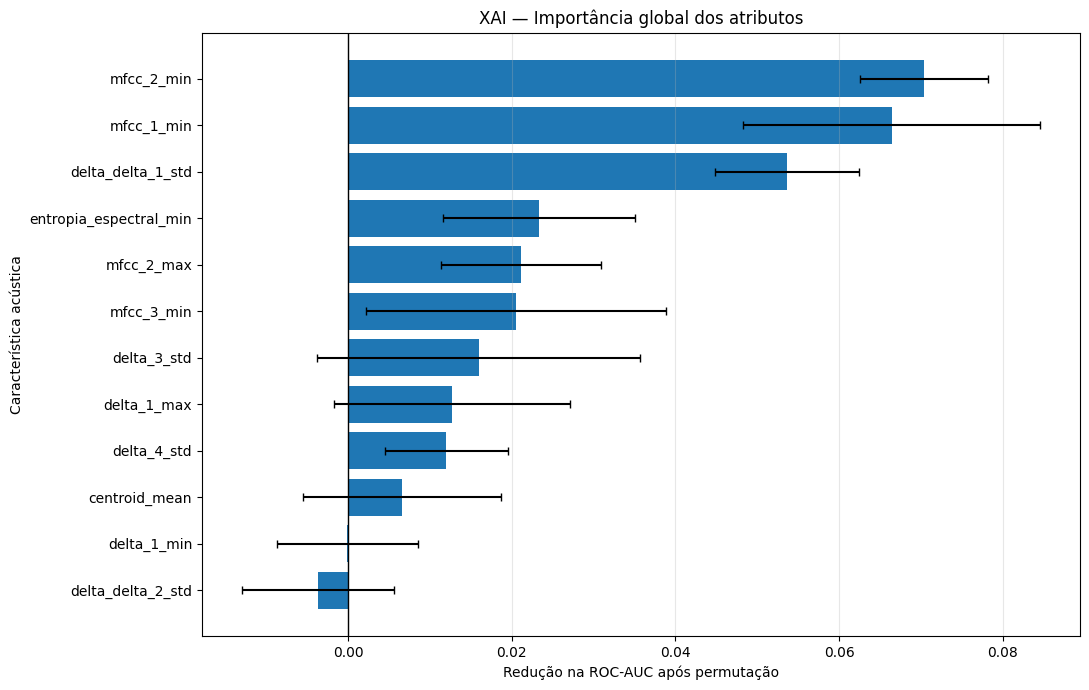

In [24]:

# ============================================================
# XAI 2 — PERMUTATION IMPORTANCE DOS 12 ATRIBUTOS
# ============================================================

N_REPETICOES = 5
rng = np.random.default_rng(42)

X_original = tabela_xai[
    atributos_xai
].to_numpy(dtype=float)

resultados_permutacao = []

for j, atributo in enumerate(atributos_xai):

    quedas_auc = []
    quedas_bal = []

    for repeticao in range(N_REPETICOES):

        X_permutado = permutar_blocos_xai(
            X_original,
            [j],
            rng
        )

        tabela_permutada = tabela_xai.copy()

        tabela_permutada.loc[
            :, atributos_xai
        ] = X_permutado

        previsoes = prever_features_xai(
            tabela_permutada
        )

        metricas = metricas_xai(previsoes)

        quedas_auc.append(
            metricas_base_xai["auc"] -
            metricas["auc"]
        )

        quedas_bal.append(
            metricas_base_xai["balanced_accuracy"] -
            metricas["balanced_accuracy"]
        )

    resultados_permutacao.append({
        "atributo": atributo,
        "queda_auc_media": np.mean(quedas_auc),
        "desvio_auc": np.std(quedas_auc),
        "queda_bal_media": np.mean(quedas_bal)
    })

importancia_atributos = (
    pd.DataFrame(resultados_permutacao)
    .sort_values(
        "queda_auc_media",
        ascending=False
    )
    .reset_index(drop=True)
)

display(importancia_atributos)

# Gráfico
grafico = importancia_atributos.sort_values(
    "queda_auc_media"
)

plt.figure(figsize=(11, 7))

plt.barh(
    grafico["atributo"],
    grafico["queda_auc_media"],
    xerr=grafico["desvio_auc"],
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Redução na ROC-AUC após permutação")
plt.ylabel("Característica acústica")
plt.title("XAI — Importância global dos atributos")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

,classe,categoria,queda_auc_media,desvio_auc,queda_bal_media
0,2,pig,0.068766,0.006850,0.050000
1,4,frog,0.032109,0.010021,0.034375
2,17,pouring_water,0.021703,0.013806,0.035625
3,6,hen,0.021188,0.004139,0.027500
4,14,chirping_birds,0.020266,0.005063,0.028750
5,18,toilet_flush,0.019375,0.003704,0.020625
6,15,water_drops,0.018109,0.010044,0.019375
7,10,rain,0.017719,0.007627,0.014375
8,16,wind,0.015953,0.004199,0.031875
9,7,insects,0.012437,0.001389,0.011875


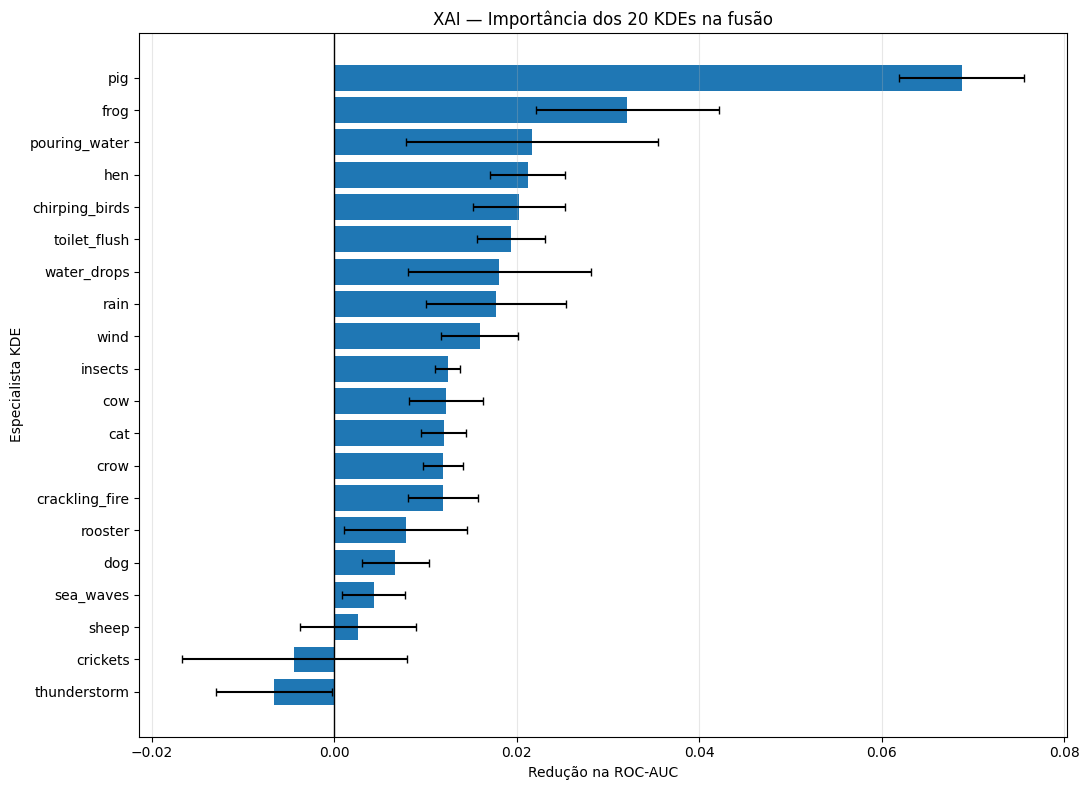

In [25]:

# ============================================================
# XAI 3 — IMPORTÂNCIA GLOBAL DOS 20 KDEs
# ============================================================

rng = np.random.default_rng(42)

resultados_kdes = []
n_classes = len(classes_xai)

for j, classe in enumerate(classes_xai):

    quedas_auc = []
    quedas_bal = []

    for repeticao in range(N_REPETICOES):

        # Duas entradas do mesmo especialista:
        # z robusto e percentil.
        X_permutado = permutar_blocos_xai(
            X_metas_xai,
            [j, j + n_classes],
            rng
        )

        previsoes = prever_metas_xai(
            X_permutado,
            tabela_xai
        )

        metricas = metricas_xai(previsoes)

        quedas_auc.append(
            metricas_base_xai["auc"] -
            metricas["auc"]
        )

        quedas_bal.append(
            metricas_base_xai["balanced_accuracy"] -
            metricas["balanced_accuracy"]
        )

    resultados_kdes.append({
        "classe": classe,
        "categoria": nomes_classes_xai.get(
            classe, str(classe)
        ),
        "queda_auc_media": np.mean(quedas_auc),
        "desvio_auc": np.std(quedas_auc),
        "queda_bal_media": np.mean(quedas_bal)
    })

importancia_kdes = (
    pd.DataFrame(resultados_kdes)
    .sort_values(
        "queda_auc_media",
        ascending=False
    )
    .reset_index(drop=True)
)

display(importancia_kdes)

grafico = importancia_kdes.sort_values(
    "queda_auc_media"
)

plt.figure(figsize=(11, 8))

plt.barh(
    grafico["categoria"],
    grafico["queda_auc_media"],
    xerr=grafico["desvio_auc"],
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Redução na ROC-AUC")
plt.ylabel("Especialista KDE")
plt.title("XAI — Importância dos 20 KDEs na fusão")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Distribuição dos resultados:


,count
tipo,
Verdadeiro negativo,147
Verdadeiro positivo,45
Falso negativo,35
Falso positivo,13



Arquivo: 5-177957-A-40.wav
Categoria real: helicopter
Tipo: Falso negativo
Score final: -1.3075
Limiar: 0.2611
Score de cada parte: [-1.45658519 -1.15840444]
Decisão: NORMAL


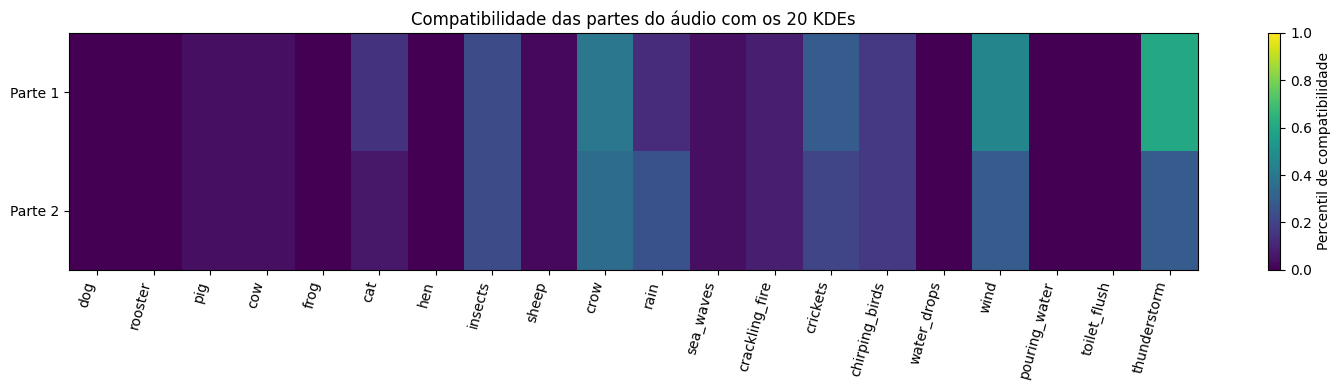

In [26]:

# ============================================================
# XAI 4 — DIAGNÓSTICO DE UM ÁUDIO
# ============================================================

from IPython.display import Audio, display
import os

# None = escolher automaticamente um falso negativo.
# Também pode informar um filename específico.
ARQUIVO_XAI = None

diagnostico = pred_xai.copy()

diagnostico["tipo"] = np.select(
    [
        (diagnostico["y_real"] == 1) &
        (diagnostico["pred_binaria"] == 0),

        (diagnostico["y_real"] == 0) &
        (diagnostico["pred_binaria"] == 1),

        (diagnostico["y_real"] == 1) &
        (diagnostico["pred_binaria"] == 1)
    ],
    [
        "Falso negativo",
        "Falso positivo",
        "Verdadeiro positivo"
    ],
    default="Verdadeiro negativo"
)

print("Distribuição dos resultados:")
display(diagnostico["tipo"].value_counts())

if ARQUIVO_XAI is None:

    erros = diagnostico[
        diagnostico["tipo"] == "Falso negativo"
    ]

    if len(erros) > 0:
        # Seleciona o falso negativo com menor score.
        caso = erros.sort_values(
            "score_anomalia"
        ).iloc[0]
    else:
        caso = diagnostico.iloc[0]

    ARQUIVO_XAI = caso["filename"]

caso = diagnostico[
    diagnostico["filename"] == ARQUIVO_XAI
].iloc[0]

tabela_caso_xai = tabela_xai[
    tabela_xai["filename"] == ARQUIVO_XAI
].copy()

if "segmento" in tabela_caso_xai.columns:
    tabela_caso_xai = tabela_caso_xai.sort_values(
        "segmento"
    )

matriz_caso_xai = construir_matriz_fusao(
    tabela_caso_xai,
    exp_xai
)

margens_caso_xai = svm_xai.decision_function(
    matriz_caso_xai
)

print("\nArquivo:", ARQUIVO_XAI)
print("Categoria real:", caso["category"])
print("Tipo:", caso["tipo"])
print("Score final:", round(caso["score_anomalia"], 4))
print("Limiar:", round(config_xai["limiar"], 4))
print("Score de cada parte:", margens_caso_xai)

print(
    "Decisão:",
    "ANOMALIA" if caso["pred_binaria"] == 1
    else "NORMAL"
)

# Percentis dos 20 especialistas.
percentis_caso = matriz_caso_xai[:, n_classes:]

rotulos_segmentos = [
    f"Parte {i+1}"
    for i in range(len(percentis_caso))
]

rotulos_kdes = [
    nomes_classes_xai.get(k, str(k))
    for k in classes_xai
]

plt.figure(figsize=(15, 4))

plt.imshow(
    percentis_caso,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Percentil de compatibilidade")
plt.xticks(
    range(n_classes),
    rotulos_kdes,
    rotation=75,
    ha="right"
)
plt.yticks(
    range(len(rotulos_segmentos)),
    rotulos_segmentos
)

plt.title(
    "Compatibilidade das partes do áudio com os 20 KDEs"
)
plt.tight_layout()
plt.show()

# Ouvir o arquivo original.
caminho_audio_xai = os.path.join(
    PASTA_AUDIO, ARQUIVO_XAI
)

if os.path.isfile(caminho_audio_xai):
    display(Audio(filename=caminho_audio_xai))

Valor de referência: -0.5517
Score reconstruído: -1.3075
Score original: -1.3075
Limiar de decisão: 0.26112991108832945


,classe,categoria,shap_z,shap_percentil,contribuicao_total,magnitude
13,13,crickets,-0.269056,-0.256531,-0.525586,0.525586
19,19,thunderstorm,0.008325,-0.194572,-0.186247,0.186247
8,8,sheep,-0.067964,-0.061265,-0.129229,0.129229
6,6,hen,-0.092118,-0.033413,-0.125531,0.125531
10,10,rain,0.089246,-0.004716,0.084530,0.084530
16,16,wind,-0.040494,0.124711,0.084217,0.084217
11,11,sea_waves,-0.056490,-0.011918,-0.068408,0.068408
4,4,frog,0.054998,0.013230,0.068228,0.068228
17,17,pouring_water,0.045833,0.013994,0.059827,0.059827
2,2,pig,-0.041849,-0.003153,-0.045002,0.045002


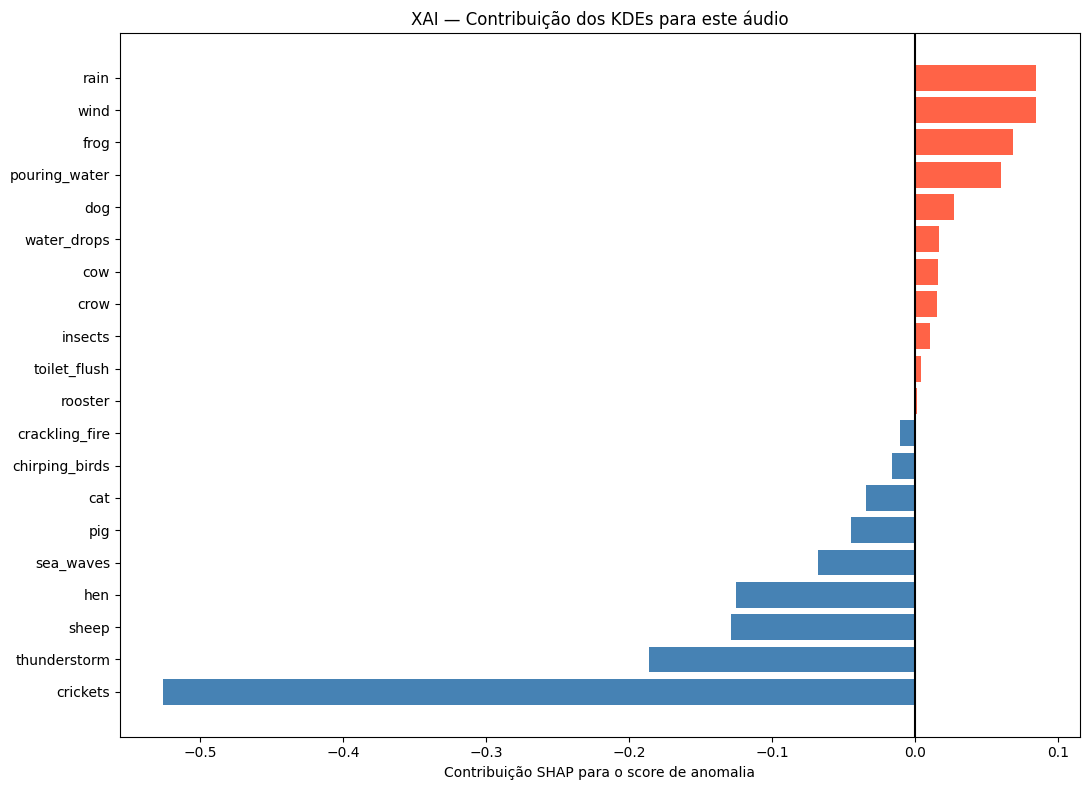

In [27]:

# ============================================================
# XAI 5 — SHAP SOBRE A FUSÃO KDE + SVM
# ============================================================

import sys
import subprocess

try:
    import shap
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "-q", "install", "shap"
    ])
    import shap

rng = np.random.default_rng(42)

# Background do fold 4.
n_fundo = min(25, len(fundo_metas_xai))

indices = rng.choice(
    len(fundo_metas_xai),
    size=n_fundo,
    replace=False
)

background = fundo_metas_xai[indices]

explainer_svm = shap.Explainer(
    svm_xai.decision_function,
    shap.maskers.Independent(background),
    algorithm="permutation",
    seed=42
)

valores_shap = explainer_svm(
    matriz_caso_xai,
    max_evals=(2 * matriz_caso_xai.shape[1] + 1) * 3
)

contrib_segmentos = np.asarray(
    valores_shap.values
)

bases_segmentos = np.asarray(
    valores_shap.base_values
).reshape(-1)

# Reproduzir a agregação escolhida no notebook.
if config_xai["agregacao"] == "mean":
    contribuicoes = contrib_segmentos.mean(axis=0)
    valor_base = bases_segmentos.mean()
    score_explicado = margens_caso_xai.mean()

elif config_xai["agregacao"] == "max":
    idx = np.argmax(margens_caso_xai)
    contribuicoes = contrib_segmentos[idx]
    valor_base = bases_segmentos[idx]
    score_explicado = margens_caso_xai[idx]

else:
    raise ValueError("Agregação não suportada")

# Conferir a reconstrução SHAP.
reconstruido = valor_base + contribuicoes.sum()

print("Valor de referência:", round(valor_base, 4))
print("Score reconstruído:", round(reconstruido, 4))
print("Score original:", round(score_explicado, 4))
print("Limiar de decisão:", config_xai["limiar"])

assert np.isclose(
    reconstruido,
    score_explicado,
    atol=1e-3
)

# Somar as duas contribuições de cada KDE.
tabela_shap_kde = pd.DataFrame({
    "classe": classes_xai,
    "categoria": [
        nomes_classes_xai.get(k, str(k))
        for k in classes_xai
    ],
    "shap_z": contribuicoes[:n_classes],
    "shap_percentil": contribuicoes[n_classes:]
})

tabela_shap_kde["contribuicao_total"] = (
    tabela_shap_kde["shap_z"] +
    tabela_shap_kde["shap_percentil"]
)

tabela_shap_kde["magnitude"] = (
    tabela_shap_kde["contribuicao_total"].abs()
)

tabela_shap_kde = tabela_shap_kde.sort_values(
    "magnitude",
    ascending=False
)

display(tabela_shap_kde)

# Gráfico de contribuições.
grafico = tabela_shap_kde.sort_values(
    "contribuicao_total"
)

plt.figure(figsize=(11, 8))

cores = [
    "tomato" if v > 0 else "steelblue"
    for v in grafico["contribuicao_total"]
]

plt.barh(
    grafico["categoria"],
    grafico["contribuicao_total"],
    color=cores
)

plt.axvline(0, color="black")
plt.xlabel("Contribuição SHAP para o score de anomalia")
plt.title("XAI — Contribuição dos KDEs para este áudio")
plt.tight_layout()
plt.show()

Score real: -1.3075
Score reconstruído: -1.3075


,atributo,contribuicao_shap,magnitude
3,mfcc_3_min,-0.513642,0.513642
2,mfcc_2_min,0.354426,0.354426
11,delta_1_max,-0.189141,0.189141
7,entropia_espectral_min,-0.176714,0.176714
10,delta_4_std,-0.155760,0.155760
8,delta_1_min,-0.101598,0.101598
0,delta_delta_1_std,-0.089205,0.089205
6,mfcc_2_max,0.053949,0.053949
1,delta_3_std,-0.043467,0.043467
9,delta_delta_2_std,-0.033272,0.033272


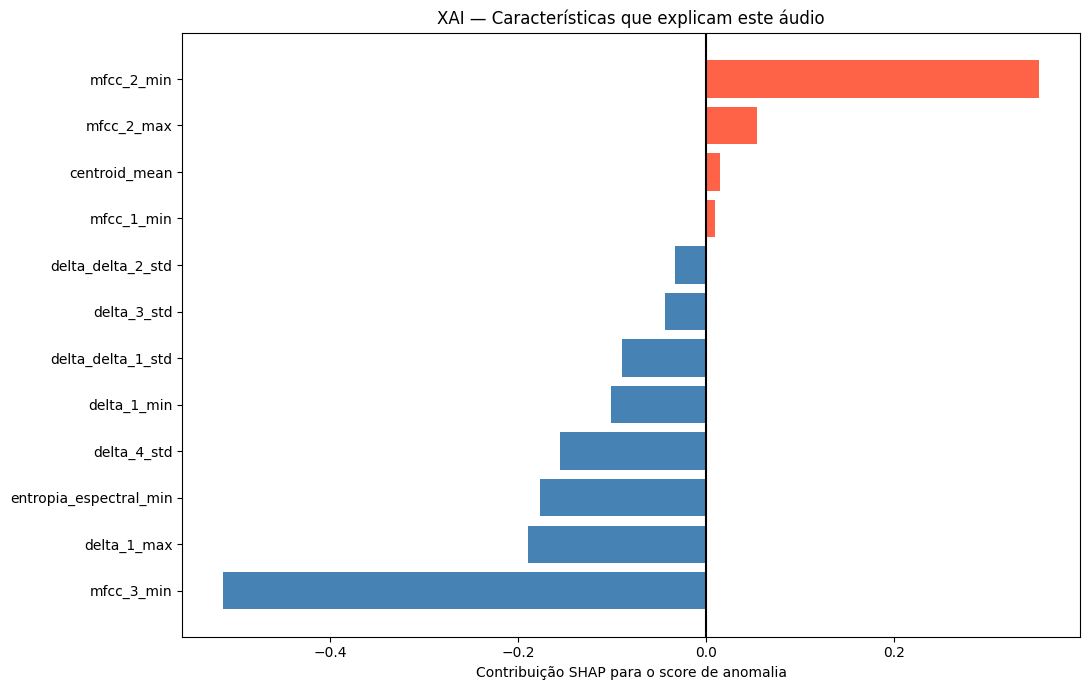

In [28]:

# ============================================================
# XAI 6 — SHAP DOS ATRIBUTOS ACÚSTICOS ORIGINAIS
# ============================================================

# Função que executa todo o pipeline treinado.
def prever_score_atributos(X):

    X = np.asarray(X, dtype=float)

    entrada = pd.DataFrame(
        X,
        columns=atributos_xai
    )

    matriz = construir_matriz_fusao(
        entrada,
        exp_xai
    )

    return svm_xai.decision_function(matriz)


# Background com áudios do fold de desenvolvimento.
fundo_atributos = selecionar_particao(
    df_xai, "desenv"
)[atributos_xai].to_numpy(dtype=float)

rng = np.random.default_rng(42)

indices_fundo = rng.choice(
    len(fundo_atributos),
    size=min(20, len(fundo_atributos)),
    replace=False
)

background_atributos = fundo_atributos[
    indices_fundo
]

X_audio = tabela_caso_xai[
    atributos_xai
].to_numpy(dtype=float)

# SHAP completo.
explainer_atributos = shap.Explainer(
    prever_score_atributos,
    shap.maskers.Independent(background_atributos),
    algorithm="permutation",
    feature_names=atributos_xai,
    seed=42
)

shap_atributos = explainer_atributos(
    X_audio,
    max_evals=(2 * len(atributos_xai) + 1) * 2
)

valores = np.asarray(
    shap_atributos.values
)

bases = np.asarray(
    shap_atributos.base_values
).reshape(-1)

if config_xai["agregacao"] == "mean":
    contrib_atributos = valores.mean(axis=0)
    base_atributos = bases.mean()
    score_alvo = margens_caso_xai.mean()
else:
    idx = np.argmax(margens_caso_xai)
    contrib_atributos = valores[idx]
    base_atributos = bases[idx]
    score_alvo = margens_caso_xai[idx]

tabela_shap_atributos = pd.DataFrame({
    "atributo": atributos_xai,
    "contribuicao_shap": contrib_atributos
})

tabela_shap_atributos["magnitude"] = (
    tabela_shap_atributos[
        "contribuicao_shap"
    ].abs()
)

tabela_shap_atributos = (
    tabela_shap_atributos
    .sort_values("magnitude", ascending=False)
)

print("Score real:", round(score_alvo, 4))
print(
    "Score reconstruído:",
    round(base_atributos + contrib_atributos.sum(), 4)
)

assert np.isclose(
    base_atributos + contrib_atributos.sum(),
    score_alvo,
    atol=1e-3
)

display(tabela_shap_atributos)

grafico = tabela_shap_atributos.sort_values(
    "contribuicao_shap"
)

cores = [
    "tomato" if v > 0 else "steelblue"
    for v in grafico["contribuicao_shap"]
]

plt.figure(figsize=(11, 7))

plt.barh(
    grafico["atributo"],
    grafico["contribuicao_shap"],
    color=cores
)

plt.axvline(0, color="black")
plt.xlabel("Contribuição SHAP para o score de anomalia")
plt.title("XAI — Características que explicam este áudio")
plt.tight_layout()
plt.show()

KDE selecionado: 19 thunderstorm
Segmento investigado: 2
Bandwidth: 0.63139
Log-densidade KDE: -15.2992
Log-densidade reconstruída: -15.2992
Número efetivo aproximado de kernels: 1.83


,atributo,penalidade_kde
10,delta_4_std,1.797180
5,mfcc_1_min,1.574867
11,delta_1_max,0.703987
6,mfcc_2_max,0.638770
4,centroid_mean,0.634165
0,delta_delta_1_std,0.266985
1,delta_3_std,0.213350
8,delta_1_min,0.206740
7,entropia_espectral_min,0.153501
9,delta_delta_2_std,0.132571


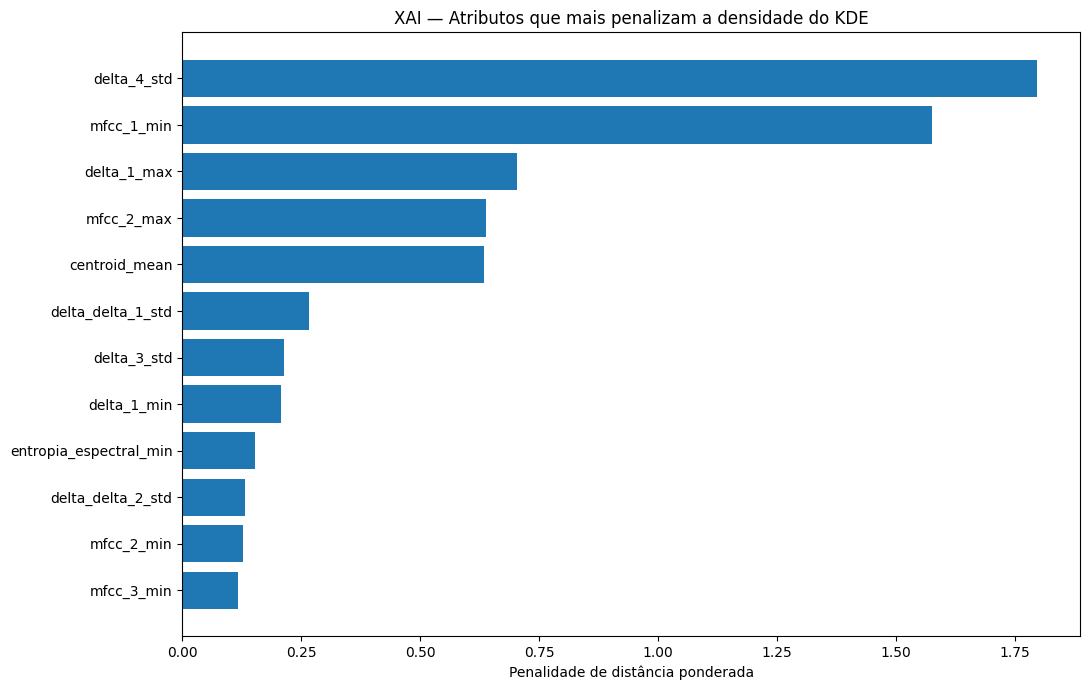

In [29]:

# ============================================================
# XAI 7 — DECOMPOSIÇÃO MATEMÁTICA INTERNA DO KDE
# ============================================================

from scipy.special import logsumexp

# KDE que apresentou o maior percentil médio.
medias_percentis = percentis_caso.mean(axis=0)

indice_kde = int(np.argmax(medias_percentis))
classe_kde = classes_xai[indice_kde]

# Segmento com maior score de anomalia.
indice_segmento = int(
    np.argmax(margens_caso_xai)
)

kde = exp_xai["modelos"][classe_kde]
scaler = exp_xai["scalers"][classe_kde]

# Recuperar os dados originais usados para treinar o KDE.
treino_kde = selecionar_particao(
    df_xai, "treino"
)

treino_kde = treino_kde[
    treino_kde["target"] == classe_kde
]

X_treino_kde = scaler.transform(
    treino_kde[atributos_xai].to_numpy(dtype=float)
)

# Áudio investigado, no espaço padronizado.
x = scaler.transform(
    tabela_caso_xai.iloc[
        [indice_segmento]
    ][atributos_xai].to_numpy(dtype=float)
)[0]

h = float(kde.bandwidth)

# Distâncias quadráticas por atributo.
diferencas_quadradas = (
    X_treino_kde - x
) ** 2

# Log-kernel para cada amostra de treinamento.
log_kernels = (
    -diferencas_quadradas.sum(axis=1) /
    (2 * h**2)
)

# Pesos normalizados dos kernels.
pesos = np.exp(
    log_kernels - logsumexp(log_kernels)
)

# Penalidade média de cada atributo, ponderada
# pela contribuição de cada kernel.
penalidades = (
    pesos[:, None] *
    diferencas_quadradas /
    (2 * h**2)
).sum(axis=0)

tabela_penalidades = pd.DataFrame({
    "atributo": atributos_xai,
    "penalidade_kde": penalidades
}).sort_values(
    "penalidade_kde",
    ascending=False
)

# Reconstrução matemática exata da log-densidade.
n, d = X_treino_kde.shape

pesos_positivos = pesos[pesos > 0]

entropia_pesos = -np.sum(
    pesos_positivos * np.log(pesos_positivos)
)

score_reconstruido = (
    -np.log(n)
    -(d / 2) * np.log(2 * np.pi * h**2)
    -penalidades.sum()
    +entropia_pesos
)

score_original = kde.score_samples(
    x.reshape(1, -1)
)[0]

assert np.isclose(
    score_reconstruido,
    score_original,
    atol=1e-5
)

print(
    "KDE selecionado:",
    classe_kde,
    nomes_classes_xai.get(classe_kde)
)
print("Segmento investigado:", indice_segmento + 1)
print("Bandwidth:", round(h, 5))
print("Log-densidade KDE:", round(score_original, 5))
print(
    "Log-densidade reconstruída:",
    round(score_reconstruido, 5)
)
print(
    "Número efetivo aproximado de kernels:",
    round(1 / np.sum(pesos**2), 2)
)

display(tabela_penalidades)

grafico = tabela_penalidades.sort_values(
    "penalidade_kde"
)

plt.figure(figsize=(11, 7))

plt.barh(
    grafico["atributo"],
    grafico["penalidade_kde"]
)

plt.xlabel("Penalidade de distância ponderada")
plt.title(
    "XAI — Atributos que mais penalizam a densidade do KDE"
)
plt.tight_layout()
plt.show()